In [1]:
import pickle
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr
import matplotlib.pyplot as plt
import sys
sys.path.append('../../../')
from helper_function import *
cobra.Configuration.solver = "glpk"
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

In [ ]:
M_corr = []
C_corr = []
C_cv = []

for i in range(20):
    with open(f'../../../FBAsolution/Perturb_P/M9_sufficient_423_1_proteome_{i+1}_by_model.pkl', 'rb') as pickle_file:
        data = pickle.load(pickle_file)
        all_total_nutrient_count = data['all_total_nutrient_count']
        all_total_intake = data['all_total_intake']
        all_growth_rate = data['all_growth_rate']
        all_random_medium = data['all_random_medium']
        all_met_flux = data['all_met_flux']
        del data

    M_corr.append(pearsonr(all_total_nutrient_count[all_growth_rate > 0.001], all_growth_rate[all_growth_rate > 0.001]))
    C_corr.append(pearsonr(all_total_intake[all_growth_rate > 0.001], all_growth_rate[all_growth_rate > 0.001]))

    x = (all_total_intake[0][all_growth_rate[0] > 0.001]) / 5
    cv = np.std(x) / np.mean(x)
    C_cv.append(cv)
    


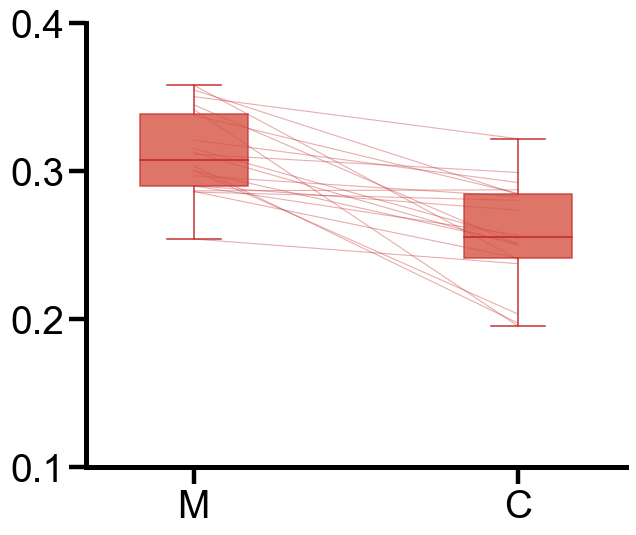

In [4]:
set_panel_style(scale=4)

cmap = plt.get_cmap("coolwarm")
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]

complex_line_color    = colors[19]
complex_scatter_color = colors[18]

plt.figure(figsize=(7, 6))

ax = plt.gca()

# === paired lines ===
for i in range(len(M_corr)):
    ax.plot(
        [1, 2.5],
        [M_corr[i][0], C_corr[i][0]],
        color=complex_line_color,
        linewidth=0.8,
        alpha=0.4,
        zorder=1
    )

# === boxplot ===
ax.boxplot(
    [[M_corr[i][0] for i in range(len(M_corr))],
     [C_corr[i][0] for i in range(len(C_corr))]],
    positions=[1, 2.5],
    widths=0.5,
    patch_artist=True,
    boxprops=dict(
        facecolor=complex_scatter_color,
        color=complex_line_color,
        alpha=0.8,
        linewidth=1.1
    ),
    whiskerprops=dict(color=complex_line_color, linewidth=1.1),
    capprops=dict(color=complex_line_color, linewidth=1.1),
    medianprops=dict(color=complex_line_color, linewidth=1.3),
    flierprops=dict(markeredgecolor=complex_line_color)
)

plt.xticks([1, 2.5], ['M', 'C'])

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.ylim(0.1, 0.4)

plt.tight_layout()
#plt.savefig("Supp_Figure5_perturbP.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
plt.show()


# Sector-growth correlation

In [5]:
def node_proteome_cost(met_flux, node_id, cluster_nodes):
        
    grouped_rec = [rec for rec in cluster_nodes[node_id] if 'EX_' not in rec]
    #grouped_flux = {rec: value for rec, value in met_flux if rec+'_fwd' in grouped_rec  or rec+'_bwd' in grouped_rec}

    grouped_flux = {rec: value for rec, value in met_flux if (rec+'_fwd' in grouped_rec and value > 0) or (rec+'_bwd' in grouped_rec and value < 0)}

    node_proteome_cost = 0
    for rec, flux in grouped_flux.items():
        proteome_cost = abs(flux)
        node_proteome_cost += proteome_cost

    return node_proteome_cost

def graph_node_proteome_cost(met_flux, cluster_nodes):
    graph_proteome_cost = {}

    for node_id in range(20):
        temp = node_proteome_cost(met_flux, node_id, cluster_nodes)
        graph_proteome_cost[node_id] = temp

    return graph_proteome_cost

from typing import List, Tuple, Optional
from dataclasses import dataclass

@dataclass
class Sample:
    E: np.ndarray      # shape (n,)
    Y: float

from typing import List, Tuple, Optional
from dataclasses import dataclass


def build_samples_from_origin(all_met_flux, all_growth_rate, all_total_nutrient_count, cluster_nodes) -> List[Sample]:
    samples = []
    for j in range(len(all_met_flux)):
        for i in range(len(all_met_flux[j])):
            if all_growth_rate[j][i] == 0:
                continue
            E_tmp = list(graph_node_proteome_cost(all_met_flux[j][i], cluster_nodes).values())
            try:
                with np.errstate(divide='raise', invalid='raise'):
                    E_arr = np.asarray(E_tmp, dtype=float)
                    E = E_arr / E_arr.sum()
            except FloatingPointError:
                continue

            total_proteome = sum([abs(value) for key, value in all_met_flux[j][i]])
            Y = all_growth_rate[j][i] #/ total_proteome * 1000
            samples.append(Sample(E=np.asarray(E, dtype=float),
                                Y=Y))
    return samples

In [6]:
total_sector_corr = np.array([[0.0 for _ in range(20)] for _ in range(20)])
total_P_across_species = []

set_panel_style(scale=4)
with open('../../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

for i in range(20):
    with open(f'../../../FBAsolution/Perturb_P/M9_sufficient_423_1_proteome_{i+1}_by_model.pkl', 'rb') as pickle_file:
        data = pickle.load(pickle_file)
        all_total_nutrient_count = data['all_total_nutrient_count']
        all_total_intake = data['all_total_intake']
        all_growth_rate = data['all_growth_rate']
        all_random_medium = data['all_random_medium']
        all_met_flux = data['all_met_flux']
        del data
    
    P_across_species = [sum(abs(flux) for rec, flux in met_flux if rec not in shared_medium) for met_flux in all_met_flux[0]]

    total_P_across_species.append(P_across_species)

    samples = build_samples_from_origin(all_met_flux, all_growth_rate, all_total_nutrient_count, cluster_nodes)
    for j in range(20):
        total_sector_corr[i, j] = spearmanr(np.array([x.E for x in samples]).T[j], np.array([x.Y for x in samples])).correlation

In [7]:
P_mat = np.array(total_P_across_species, dtype=float)
corr_mat = np.array(total_sector_corr, dtype=float)


with open('../../Figure4/corr_in_silico_complex.pkl', 'rb') as f:
    corr_in_silico_complex = pickle.load(f)
baseline_corr = np.array([x[0] for x in corr_in_silico_complex], dtype=float)

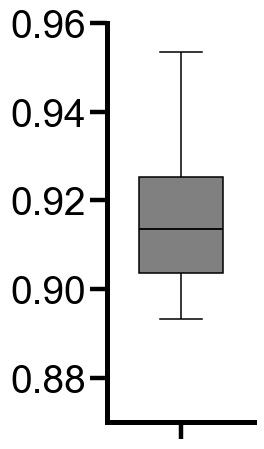

In [8]:
rank_stability = []

for i in range(corr_mat.shape[0]):
    rho, p = spearmanr(
        baseline_corr,
        corr_mat[i, :]
    )
    rank_stability.append(rho)

rank_stability = np.array(rank_stability)


plt.figure(figsize=(3.5, 5))

sns.boxplot(
    data=rank_stability,
    width=0.8,
    showfliers=False,
    boxprops=dict(facecolor="gray", edgecolor="black", linewidth=1.1),
    whiskerprops=dict(color="black", linewidth=1.1),
    capprops=dict(color="black", linewidth=1.1),
    medianprops=dict(color="black", linewidth=1.3)
)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlim(-0.7, 0.7)
ax.set_ylim(0.87, 0.96)

plt.tight_layout()

plt.show()